In [1]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import numpy as np


In [3]:
!rm -rf colab_llm_utils

In [4]:
!git clone -b multiaxial https://github.com/ravy101/colab_llm_utils.git

Cloning into 'colab_llm_utils'...
remote: Enumerating objects: 1564, done.
remote: Counting objects: 100% (86/86), done.
remote: Compressing objects: 100% (60/60), done.
remote: Total 1564 (delta 51), reused 58 (delta 26), pack-reused 1478 (from 2)
Receiving objects: 100% (1564/1564), 1.05 MiB | 12.66 MiB/s, done.
Resolving deltas: 100% (996/996), done.


In [5]:
%%capture
!pip install datasets transformers evaluate rouge_score accelerate
!pip install git+https://github.com/google-research/bleurt.git
!pip install --upgrade bitsandbytes

In [6]:
from google.colab import userdata
HF_TOKEN = userdata.get('HF_TOKEN')

In [7]:
import colab_llm_utils
from importlib import reload
reload(colab_llm_utils)

<module 'colab_llm_utils' from '/content/colab_llm_utils/__init__.py'>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import random
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification, AutoConfig, BitsAndBytesConfig, GenerationConfig
from accelerate import infer_auto_device_map, init_empty_weights

In [9]:

from scipy import stats
import re
import sys
import gc
import os
import string
import math
from datetime import datetime

In [10]:
import torch
from torch.nn import functional as F


In [14]:


model_config = colab_llm_utils.configs.models.qwen3_8b
large_model_config = colab_llm_utils.configs.models.llama33_70b_chat
embedding_model_config = colab_llm_utils.configs.models.qwen3_8b
#model_config = colab_llm_utils.configs.models.t5_ba
#large_model_config = colab_llm_utils.configs.models.t5_xl
#embedding_model_config = colab_llm_utils.configs.models.t5_base
OUTPUT_COST_RATIO = 6
tiny_cost = (4, 4*OUTPUT_COST_RATIO)
small_cost = (8, 8*OUTPUT_COST_RATIO)
large_cost = (70,70*OUTPUT_COST_RATIO)

short_name = model_config['model_name'].split('/')[-1]
short_name_large = large_model_config['model_name'].split('/')[-1]
special_tag_2 = "rag1"
#special_tag_3 = 'thinking'
special_tag_3 = "verify"
special_tag_4 = "k_shot"

base_path = "/content/drive/MyDrive/phase3/Llama"
LARGE_SUFFIX = "_large"
FILL_LARGE = False

special_tag = ""


# Get the current datetime object

# Format the datetime object into a specific string format
formatted_date = datetime.now().strftime("%Y-%m-%d_%H:%M")

In [15]:
POS_TERMS = ["INTJ",
"VERB",
"PUNCT",
"SCONJ",
"PROPN",
"NUM",
"PRON",
"AUX",
"CCONJ",
"X",
"ADJ",
"NOUN",
"ADP",
"SPACE",
"ADV",
"PART"]

CHOW = ['chow_av', 'normed_log_chow_av', 'normed_chow_quantile'] + [f'likes_q{q}' for q in
        ['0','0.1','0.2','0.3','0.4','0.5','0.6','0.7','0.8','0.9']]

In [16]:
# filters were good on 3b chat xsum and cnn
filt_none = []
#filt_1a = ["SPACE", "PUNCT", "NUM", "PRON", "NOUN", "X", "ADP"]
#filt_1b = ["SPACE", "PUNCT", "NUM", "PRON", "AUX", "VERB", "PROPN", "INTJ"]
SEM_POS_FILTER = filt_none
LEX_POS_FILTER = filt_none
POS_POS_FILTER =filt_none
EX_TAG = "_stack"
#EX_TAG = ""
STRICTNESS = .3#.5
DISTANCE_LIMIT = 5

dataset_list = [#colab_llm_utils.configs.datasets.triviaqa,
                #colab_llm_utils.configs.datasets.routerbench_10k,
                #colab_llm_utils.configs.datasets.strategyqa
                #colab_llm_utils.configs.datasets.arc_challenge,
                colab_llm_utils.configs.datasets.mixeval_ff,
                #colab_llm_utils.configs.datasets.sciq,
                #colab_llm_utils.configs.datasets.nqopen,
                #colab_llm_utils.configs.datasets.hotpotqa,
                #colab_llm_utils.configs.datasets.cnn_dailymail,
                #colab_llm_utils.configs.datasets.wmt14de,
                #colab_llm_utils.configs.datasets.wmt19de,
                #colab_llm_utils.configs.datasets.wmt14
                #colab_llm_utils.configs.datasets.xsum,
                #colab_llm_utils.configs.datasets.samsum
                ]

dataframes = []
emb_dicts = []
auc_tables = []
all_results = []
for dataset in dataset_list:
  drive_path = os.path.join(base_path, dataset["clean_name"])
  results_path = os.path.join(base_path, "results", dataset['clean_name'])
  if not os.path.exists(results_path):
    os.makedirs(results_path)
  results_tag = f"MS:{short_name}{special_tag}ML{short_name_large}{formatted_date}"
  DICT_ANS = dataset['dict_ans']
  SELF_CONF = False
  PTRUE = False
  if PTRUE:
    short_name = short_name + "ptrue"

  if SELF_CONF:
    short_name = short_name + "conf"

  #TODO add metric to dataset config
  if dataset['task_type'] == 'multiple_choice':
    METRIC = 'rouge'
  else:
    METRIC = 'gpt_score'
    METRIC = "is_correct"
    #METRIC = "f1"
  #METRIC = 'is_correct'
  METRIC = "gpt_score"
  #METRIC = 'em'

  df1 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag}{EX_TAG}.pickle"))
  df2 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag_2}{EX_TAG}.pickle"))
  df3 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag_3}{EX_TAG}.pickle"))
  df5 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name_large}{""}{EX_TAG}.pickle"))
  df4 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag_4}{EX_TAG}.pickle"))
  df1["correct"] = (df1[METRIC] > .01).astype(float)
  try:
    df2["correct"] = (df2[METRIC] > .01).astype(float)
  except:
    df2["correct"] = (df2["f1"] > .01).astype(float)
  #df3["correct"] = (df3[METRIC] > .01).astype(float)
  df4["correct"] = (df4[METRIC] > .01).astype(float)

  dataframes.append(df1)
  dataframes.append(df2)
  dataframes.append(df3)

  dataframes.append(df4)
  dataframes.append(df5)

  for df in dataframes:
    colab_llm_utils.misc.extra_cols(df)


  print(f"Dataset: {dataset['clean_name']}")
  print(f"Model: {model_config['model_name']}")




  conf_metrics = ['chow_quantile', 'log_chow_av'] # baselines

  DO_EMB_DICTS = False
  if DO_EMB_DICTS:
    tokenizer = AutoTokenizer.from_pretrained(embedding_model_config['model_name'], token = HF_TOKEN)
    stopword_ids = set()
    embedding_layer = colab_llm_utils.model_tools.get_or_load_embedding(base_path, embedding_model_config, input_embeddings = True)
    embedder = colab_llm_utils.model_tools.tokenizer_embedder(embedding_layer, tokenizer)
    emb_dict, pos_dict = colab_llm_utils.confidence.get_embedding_pos_dicts(df1, embedder, tokenizer)
    emb_dicts.append(emb_dict)

  if PTRUE:
    conf_metrics = conf_metrics + ['p_true']

  DO_ABLATIONS = False
  if DO_ABLATIONS:
    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict, pos_dict, tokenizer, position_correct = False, collapse_prefix = True, sim_thresh = 2, allow_empty = True, lex_pos_filt= LEX_POS_FILTER, bidir_col = False, sem_pos_filt=SEM_POS_FILTER, tag = 'just_collapse')
    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict,  pos_dict, tokenizer, position_correct = True, collapse_prefix = False, distance_limit= DISTANCE_LIMIT, sim_thresh = 2, pos_pos_filt=POS_POS_FILTER, future_sim_thresh=1.6, tag = 'just_position')
    conf_metrics = conf_metrics + ['just_position_cs_log_chow_av', 'just_collapse_cs_log_chow_av']

  DO_THRESH = False
  if DO_THRESH:

    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict,  pos_dict, tokenizer, position_correct = True, distance_limit=DISTANCE_LIMIT, collapse_prefix = True, sim_thresh = STRICTNESS, bidir_col = False, clip = 1,
                                                   allow_empty = True, lex_pos_filt= LEX_POS_FILTER, sem_pos_filt=SEM_POS_FILTER, pos_pos_filt=POS_POS_FILTER, future_sim_thresh=1.6, tag = 'full_thresh') #.4
    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict,  pos_dict, tokenizer, position_correct = False, collapse_prefix = False, sim_thresh = STRICTNESS, allow_empty = True, lex_pos_filt= LEX_POS_FILTER, sem_pos_filt=SEM_POS_FILTER, tag = 'base_thresh')
    conf_metrics = conf_metrics + ['full_thresh_cs_log_chow_av',  'base_thresh_cs_log_chow_av']
    tab, quant_cols = colab_llm_utils.likelihood.quantile_analysis(df1, 'full_thresh_cs_likes', METRIC)


  DO_CS = False
  if DO_CS:
    colab_llm_utils.confidence.get_cs_emb_likes(df1, emb_dict, tokenizer,  position_correct = False,  distance_limit=3, collapse_prefix = False, sim_adjust = 1, tag = 'base')
    colab_llm_utils.confidence.get_cs_emb_likes(df1, emb_dict, tokenizer,  position_correct = True, distance_limit=3,  collapse_prefix = True, sim_adjust = .5, tag = 'full_5')
    colab_llm_utils.confidence.get_cs_emb_likes(df1, emb_dict, tokenizer, position_correct = True, distance_limit=3, collapse_prefix = True, sim_adjust = 1, tag = 'full')
    conf_metrics = conf_metrics + ['base_cs_log_chow_av', 'full_cs_log_chow_av', 'full_5_cs_log_chow_av']


  if SELF_CONF:
    conf_metrics = conf_metrics + ['self_conf']
  #conf_metrics = ['chow_av','log_chow_av'] + list(df.columns[-80:])
  conf_metrics = list(set(conf_metrics))



  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df1, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df2, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df3, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df4, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df5, 'likes', METRIC)

  def calc_chows(df):
    df['mean_prob'] = colab_llm_utils.misc.norm_series(df['chow_av'], invert=True)
    df['normed_log_chow_av'] = colab_llm_utils.misc.norm_series(df['log_chow_av'], invert = True)
    df['normed_chow_quantile'] = colab_llm_utils.misc.norm_series(df['chow_quantile'], invert = True)

  for df in dataframes:
    calc_chows(df)


  print(short_name)
  print(dataset['clean_name'])
  cor_table = df1[conf_metrics + [METRIC]].corr(numeric_only=True)[METRIC].abs().sort_values(ascending=False)
  cor_table.to_csv(os.path.join(results_path, results_tag + "correlation1.csv"), index=True, header=True, float_format="%.6f")
  with open(os.path.join(results_path, results_tag + "correlation1.txt"), 'w') as f:
      # Convert dataframe to latex string and write to file
      f.write(cor_table.to_latex(index=True,
                                    caption='Correlation Table',
                                    label='tab:results',
                                    column_format='lrc'))
  cor_table


  DELEGATE_COLUMNS = ["random", 'normed_chow_quantile', 'normed_log_chow_av']
  CLEAN_NAME_DICT ={"random":'Random',
                    "normed_chow_quantile":"Quantile (.5)",
                    "normed_log_chow_av":"Chow Av.",
                    "n_cvar":"CVaR",
                    "collapse": "Lex. Collapse",
                    "t_embed": "Sem. Collapse",
                    "embed": "Sem. Dist",
                    "position": "Pos. Collapse",
                    "t_full": "Full",
                    "p_true_n": "P(True)",
                    "full": "Dist Full",
                    "post_hoc": "Post-hoc Model",
                    "post_hoc2": "Post-hoc Baselines",
                    "cvar": "CVaR",
                    "full_cvar": "Full Dist. CVaR",
                    "t_full_cvar": "Full CVaR",
                    "prod_av": "prod av",
                    "post_hoc_lm":"PH LM",
                    "post_hoc_conf": "PH LM Single",
                    "router_lm": "Router",}

  METRIC_DICT = {"f1": "F1 Score", "gpt_score": "GPT Score", "gpt_score_cont": "GPT Score", "bem": "BEM", "em": "EM", "bleurt": "BLEURT", "meteor": "METEOR", "rouge": "Rouge-L", "is_correct": "Score", "correct": "Score"}


  if DO_ABLATIONS:
    df1['collapse'] = colab_llm_utils.misc.norm_series(df1['just_collapse_cs_log_chow_av'], invert=True)
    df1['position'] = colab_llm_utils.misc.norm_series(df1['just_position_cs_log_chow_av'], invert=True)
    DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['collapse', 'position',]


  if DO_THRESH:
    df1['t_full'] = colab_llm_utils.misc.norm_series(df1['full_thresh_cs_log_chow_av'], invert=True)
    df1['t_full_cvar'] = colab_llm_utils.misc.norm_series(df1['full_thresh_cs_cvar'], invert=True)
    df1['t_embed'] =  colab_llm_utils.misc.norm_series(df1['base_thresh_cs_log_chow_av'], invert=True)
    DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['t_embed', 't_full']

  for df in dataframes:
    df.reset_index(inplace=True)



  #DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['post_hoc_lm']

Dataset: MixEval-FF
Model: Qwen/Qwen3-8B
Qwen3-8B
MixEval-FF


In [17]:
for d in dataframes:

  print(f"acc start: {d[:2000][METRIC].mean()} ")
  print(f"acc end: {d[2000:][METRIC].mean()}")

acc start: 0.5145 
acc end: 0.7765
acc start: 0.619 
acc end: 0.7445
acc start: 0.5695 
acc end: 0.7755
acc start: 0.622 
acc end: 0.7735
acc start: 0.8035 
acc end: 0.828


GPT SCORE ON top and tail mixeval
acc start: 0.5475
acc end: 0.7755
acc start: 0.6355
acc end: 0.7375
acc start: 0.493
acc end: 0.7755
acc start: 0.8035
acc end: 0.828
acc start: 0.5975
acc end: 0.7735

In [18]:
#idx = ((df3['ans'] == df1['ans']) & (df2['ans'] == df1['ans']) & (df4['ans'] == df1['ans']))
#idx = ((df2['ans'] == df1['ans']) & (df4['ans'] == df1['ans']))
min_len = min([len(df) for df in dataframes])
df1 = df1[:min_len]
df2 = df2[:min_len]
df3 = df3[:min_len]
df4 = df4[:min_len]
df5 = df5[:min_len]

for df in dataframes:
  df[METRIC]
  print(df.shape)

(4000, 46)
(4000, 48)
(4000, 48)
(4000, 48)
(4000, 47)


In [19]:
df1['correct'] = df1[METRIC]
df2['correct'] = df2[METRIC]
df3['correct'] = df3[METRIC]
df4['correct'] = df4[METRIC]
df5['correct'] = df5[METRIC]

/tmp/ipykernel_673/3328941477.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['correct'] = df3[METRIC]
/tmp/ipykernel_673/3328941477.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5['correct'] = df5[METRIC]


In [20]:
for df in dataframes:
  df['correct'] = df[METRIC]


In [21]:
# clean responses keep canonical df1 prompt
df1['res_clean'] = [r[0].strip() for r in df1['responses']]
df1['prompts_clean'] = df1['prompts']

df2['res_clean'] = [r[0].strip() for r in df2['responses']]
df2['prompts_clean'] = df1['prompts_clean']

df3['res_clean'] = [r[0].strip() for r in df3['responses']]
df3['prompts_clean'] = df1['prompts_clean']

df4['res_clean'] = [r[0].strip() for r in df4['responses']]
df4['prompts_clean'] = df1['prompts_clean']

df5['res_clean'] = [r[0].strip() for r in df5['responses']]
df5['prompts_clean'] = df1['prompts_clean']

/tmp/ipykernel_673/1263264800.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['res_clean'] = [r[0].strip() for r in df3['responses']]
/tmp/ipykernel_673/1263264800.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['prompts_clean'] = df1['prompts_clean']
/tmp/ipykernel_673/1263264800.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydat

In [22]:
import numpy as np
import pandas as pd
import re
from collections import Counter

_TOKEN_RE = re.compile(r"[a-z0-9']+")

def _tokenize(s):
    return _TOKEN_RE.findall(str(s).lower())

def _text_length_stats(series, mask):
    s = series[mask].astype(str)
    if len(s) == 0:
        return {}
    words = s.str.split().apply(len)
    return {
        "n": int(len(s)),
        "char_len_mean": float(s.str.len().mean()),
        "word_len_mean": float(words.mean()),
        "word_len_med": float(words.median()),
        "pct_has_qmark": float(s.str.contains(r"\?").mean()),
        "pct_has_digit": float(s.str.contains(r"\d").mean()),
    }

def _discriminative_tokens(series, pos_mask, neg_mask, top_k=15, min_count=3, alpha=1.0):
    """Log-odds-ratio (with informative Dirichlet prior) of tokens in pos vs neg group.
    Positive score => token over-represented in the pos (recovered) group."""
    pos_tokens, neg_tokens = Counter(), Counter()
    for txt in series[pos_mask].astype(str):
        pos_tokens.update(_tokenize(txt))
    for txt in series[neg_mask].astype(str):
        neg_tokens.update(_tokenize(txt))

    vocab = set(pos_tokens) | set(neg_tokens)
    n_pos = sum(pos_tokens.values()) or 1
    n_neg = sum(neg_tokens.values()) or 1
    scores = []
    for w in vocab:
        cp, cn = pos_tokens[w], neg_tokens[w]
        if cp + cn < min_count:
            continue
        # smoothed log-odds
        lp = np.log((cp + alpha) / (n_pos + alpha)) - np.log((n_pos - cp + alpha) / (n_pos + alpha))
        ln = np.log((cn + alpha) / (n_neg + alpha)) - np.log((n_neg - cn + alpha) / (n_neg + alpha))
        scores.append((w, lp - ln, cp, cn))
    scores.sort(key=lambda t: t[1], reverse=True)
    top_pos = scores[:top_k]
    top_neg = scores[-top_k:][::-1]
    return (pd.DataFrame(top_pos, columns=["token", "log_odds", "count_recovered", "count_ref"]),
            pd.DataFrame(top_neg, columns=["token", "log_odds", "count_recovered", "count_ref"]))


def explore_recovery_text(
    origin_df,
    recovered_masks,
    base_fail,
    text_cols=("prompts", "res_clean"),
    top_k_tokens=15,
    verbose=True,
):
    """Text exploratory over recovery subsets.

    For each axis and each text column, compares RECOVERED origin-failures against
    NOT-recovered origin-failures on:
      - length/shape stats
      - discriminative tokens (over-represented in the recovered set)

    Args:
        origin_df       : origin dataframe (holds the text columns).
        recovered_masks : {axis: bool array} from explore_recovery_subsets.
        base_fail       : bool array of origin failures (meta / recompute).
        text_cols       : text columns to analyse (default prompts + res_clean).
    Returns nested dict: {axis: {col: {"length": df, "tokens_recovered": df,
                                       "tokens_ref": df}}}.
    """
    present_cols = [c for c in text_cols if c in origin_df.columns]
    missing = [c for c in text_cols if c not in origin_df.columns]
    if missing and verbose:
        print(f"[text] skipping missing columns: {missing}")

    out = {}
    for axis, rec in recovered_masks.items():
        rec = np.asarray(rec, dtype=bool)
        ref = base_fail & (~rec)          # failures this axis did NOT recover
        out[axis] = {}
        if verbose:
            print("\n" + "=" * 64)
            print(f"TEXT EXPLORATORY  |  axis '{axis}'  "
                  f"(recovered={int(rec.sum())}  not-recovered={int(ref.sum())})")
            print("=" * 64)
        for col in present_cols:
            series = origin_df[col]
            length_df = pd.DataFrame({
                "recovered": _text_length_stats(series, rec),
                "not_recovered": _text_length_stats(series, ref),
            })
            tok_pos, tok_neg = _discriminative_tokens(
                series, rec, ref, top_k=top_k_tokens
            )
            out[axis][col] = {
                "length": length_df,
                "tokens_recovered": tok_pos,
                "tokens_ref": tok_neg,
            }
            if verbose:
                print(f"\n  -- [{col}] length / shape --")
                print(length_df.round(4).to_string())
                print(f"\n  -- [{col}] tokens over-represented in RECOVERED failures --")
                print(tok_pos.round(3).to_string(index=False))
    return out

def explore_recovery_subsets(
    origin_df,
    axis_dfs,
    metric_col="correct",
    axis_names=None,
    feature_cols=None,
    text_cols=("prompts", "responses"),
    correct_thresh=0.0,          # sample is "correct" if metric_col > this
    recovery_fn=None,            # (base_score, axis_score) -> bool array; default axis>base
    top_k_features=12,
    verbose=True,
):
    """
    Exploratory diagnostic on per-axis recovery subsets for a multiaxial cascade.

    Answers, using ONLY realised outcomes (no model, no router):
      - How many origin failures does each axis recover? (recovery rate / headroom)
      - How much does each axis BREAK (correct->incorrect)? (net gain)
      - How separable are the axes? (pairwise overlap / Jaccard of recovered sets)
      - Is there OBVIOUS structure? For each numeric feature, how strongly does it
        separate 'recovered by axis A' from 'not recovered', per axis.
      - Length/text-scale effects via text_cols.

    Args:
        origin_df   : the origin (tier-0) dataframe.
        axis_dfs    : dict {axis_name: df} OR list [df, df, ...] of one-step
                      escalations, ROW-ALIGNED with origin_df.
        metric_col  : correctness/score column present in every df.
        axis_names  : optional names if axis_dfs is a list.
        feature_cols: numeric columns in origin_df to scan. If None, auto-detect.
        text_cols   : columns whose char/'word' length is used as scale features.
        correct_thresh: threshold; correct = metric_col > correct_thresh.
        recovery_fn : custom recovery definition. Default: axis correct & origin wrong.
        top_k_features: how many features to show in the ranked separation table.

    Returns a dict of DataFrames:
        'summary'      : per-axis recovery/break/net-gain counts & rates.
        'overlap'      : pairwise recovered-set overlap counts + Jaccard.
        'feature_sep'  : per (axis, feature) standardized mean-difference (recovered
                         vs base-failures-not-recovered) + simple AUROC.
        'coverage'     : how many of the origin failures are recovered by
                         (none / exactly one / multiple) axes  -> H1 separability.
    """
    # ---- normalise axis_dfs into an ordered dict ----
    if isinstance(axis_dfs, dict):
        axes = dict(axis_dfs)
    else:
        if axis_names is None:
            axis_names = [f"axis_{i}" for i in range(len(axis_dfs))]
        axes = {n: d for n, d in zip(axis_names, axis_dfs)}

    n = len(origin_df)
    for name, d in axes.items():
        if len(d) != n:
            raise ValueError(
                f"Axis '{name}' has {len(d)} rows but origin has {n}. "
                f"Row-align them first (check normalize_dfs / reset_index)."
            )

    if recovery_fn is None:
        recovery_fn = lambda base, axis: (axis == 1) & (base == 0)

    # ---- binary correctness vectors ----
    base_correct = (origin_df[metric_col].values > correct_thresh).astype(int)
    base_fail = base_correct == 0

    axis_correct = {}
    for name, d in axes.items():
        axis_correct[name] = (d[metric_col].values > correct_thresh).astype(int)

    # ---- recovered / broken masks per axis ----
    recovered = {}   # origin wrong -> axis right
    broken = {}      # origin right -> axis wrong
    for name in axes:
        ac = axis_correct[name]
        recovered[name] = recovery_fn(base_correct, ac).astype(bool)
        broken[name] = ((base_correct == 1) & (ac == 0))

    # ================= SUMMARY =================
    n_fail = int(base_fail.sum())
    rows = []
    for name in axes:
        rec = recovered[name]
        brk = broken[name]
        rows.append({
            "axis": name,
            "origin_acc": base_correct.mean(),
            "axis_acc": axis_correct[name].mean(),
            "n_origin_fail": n_fail,
            "n_recovered": int(rec.sum()),
            "recovery_rate_of_fails": rec.sum() / max(n_fail, 1),
            "n_broken": int(brk.sum()),
            "net_gain": int(rec.sum()) - int(brk.sum()),
            "net_gain_rate": (rec.sum() - brk.sum()) / n,
        })
    summary = pd.DataFrame(rows).set_index("axis")

    # ================= PAIRWISE OVERLAP (separability) =================
    names = list(axes.keys())
    ov_rows = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = names[i], names[j]
            ra, rb = recovered[a], recovered[b]
            inter = int((ra & rb).sum())
            union = int((ra | rb).sum())
            ov_rows.append({
                "axis_a": a, "axis_b": b,
                "recovered_a": int(ra.sum()),
                "recovered_b": int(rb.sum()),
                "both": inter,
                "either": union,
                "only_a": int((ra & ~rb).sum()),
                "only_b": int((rb & ~ra).sum()),
                "jaccard": inter / max(union, 1),
            })
    overlap = pd.DataFrame(ov_rows)

    # ================= COVERAGE (how many axes recover each failure) =================
    rec_matrix = np.stack([recovered[n_].astype(int) for n_ in names], axis=1)  # (n, n_axes)
    rec_count = rec_matrix.sum(axis=1)                     # per-sample #axes recovering
    fail_rec_count = rec_count[base_fail]                  # restrict to origin failures
    cov = pd.Series(fail_rec_count).value_counts().sort_index()
    coverage = pd.DataFrame({
        "n_axes_recovering": cov.index,
        "n_failures": cov.values,
        "pct_of_failures": cov.values / max(n_fail, 1),
    })
    n_unrecoverable = int((fail_rec_count == 0).sum())
    n_exclusive = int((fail_rec_count == 1).sum())         # H1 signal: single-axis-only
    n_multi = int((fail_rec_count > 1).sum())

    # ================= FEATURE SEPARATION =================
    # auto-detect numeric features if none supplied
    if feature_cols is None:
        feature_cols = [
            c for c in origin_df.columns
            if pd.api.types.is_numeric_dtype(origin_df[c])
            and c not in (metric_col, "correct", "fold")
        ]

    # add text-scale features (char + rough word count) if the text cols exist
    scale_feats = {}
    for tc in text_cols:
        if tc in origin_df.columns:
            s = origin_df[tc].astype(str)
            scale_feats[f"{tc}__char_len"] = s.str.len().values
            scale_feats[f"{tc}__word_len"] = s.str.split().apply(len).values

    feat_data = {c: origin_df[c].values for c in feature_cols}
    feat_data.update(scale_feats)

    def _std_mean_diff_and_auroc(x, group_mask, ref_mask):
        """Cohen's-d-ish standardized mean diff + rank-AUROC of x separating groups."""
        xg = x[group_mask]
        xr = x[ref_mask]
        xg = xg[~np.isnan(xg)]
        xr = xr[~np.isnan(xr)]
        if len(xg) < 3 or len(xr) < 3:
            return np.nan, np.nan
        pooled_sd = np.sqrt((np.var(xg) + np.var(xr)) / 2) or np.nan
        smd = (np.nanmean(xg) - np.nanmean(xr)) / pooled_sd if pooled_sd else np.nan
        # rank-based AUROC (prob a recovered sample scores higher than a ref sample)
        allx = np.concatenate([xg, xr])
        ranks = pd.Series(allx).rank().values
        r_g = ranks[: len(xg)].sum()
        auroc = (r_g - len(xg) * (len(xg) + 1) / 2) / (len(xg) * len(xr))
        return smd, auroc

    fs_rows = []
    for name in names:
        rec = recovered[name]
        # reference group = origin failures this axis did NOT recover
        ref = base_fail & (~rec)
        for fname, fvals in feat_data.items():
            fvals = np.asarray(fvals, dtype=float)
            smd, auroc = _std_mean_diff_and_auroc(fvals, rec, ref)
            fs_rows.append({
                "axis": name,
                "feature": fname,
                "std_mean_diff": smd,       # +ve: recovered samples have higher feature
                "sep_auroc": auroc,         # 0.5 = no separation
                "abs_sep": abs(auroc - 0.5) if not np.isnan(auroc) else np.nan,
            })
    feature_sep = (pd.DataFrame(fs_rows)
                   .sort_values(["axis", "abs_sep"], ascending=[True, False])
                   .reset_index(drop=True))

    # ================= PRINT =================
    if verbose:
        print("=" * 64)
        print(f"RECOVERY DIAGNOSTIC  |  n={n}  origin_acc={base_correct.mean():.4f}"
              f"  origin_failures={n_fail}")
        print("=" * 64)
        print("\n-- per-axis summary --")
        print(summary.round(4).to_string())
        if len(overlap):
            print("\n-- pairwise recovered-set overlap (separability) --")
            print(overlap.round(4).to_string(index=False))
        print("\n-- failure coverage (of origin failures) --")
        print(coverage.round(4).to_string(index=False))
        print(f"   unrecoverable by any axis : {n_unrecoverable} "
              f"({n_unrecoverable / max(n_fail,1):.1%})")
        print(f"   recovered by EXACTLY one  : {n_exclusive} "
              f"({n_exclusive / max(n_fail,1):.1%})   <- axis-exclusive (H1 signal)")
        print(f"   recovered by MULTIPLE     : {n_multi} "
              f"({n_multi / max(n_fail,1):.1%})   <- redundant / confounded")
        print(f"\n-- top {top_k_features} feature separations per axis "
              f"(sep_auroc away from 0.5 = obvious structure) --")
        for name in names:
            sub = feature_sep[feature_sep.axis == name].head(top_k_features)
            print(f"\n  [{name}]")
            print(sub[["feature", "std_mean_diff", "sep_auroc"]]
                  .round(4).to_string(index=False))
        print("=" * 64)


    # ================= TEXT EXPLORATORY =================
    text_report = explore_recovery_text(
        origin_df, recovered, base_fail,
        text_cols=("prompts", "res_clean"),
        verbose=verbose,
    )

    return {
        "summary": summary,
        "overlap": overlap,
        "coverage": coverage,
        "feature_sep": feature_sep,
        "text_report": text_report,          # <-- new
        "recovered_masks": recovered,
        "broken_masks": broken,
        "meta": {
            "n": n,
            "n_origin_fail": n_fail,
            "n_unrecoverable": n_unrecoverable,
            "n_exclusive": n_exclusive,
            "n_multi": n_multi,
            "axis_names": names,
        },
    }

In [23]:
res = explore_recovery_subsets(
    df1,
    {"knowledge": df2,  "review": df3,  "structure":df4},
    metric_col=METRIC,
)

RECOVERY DIAGNOSTIC  |  n=4000  origin_acc=0.6455  origin_failures=1418

-- per-axis summary --
           origin_acc  axis_acc  n_origin_fail  n_recovered  recovery_rate_of_fails  n_broken  net_gain  net_gain_rate
axis                                                                                                                  
knowledge      0.6455    0.6818           1418          475                  0.3350       330       145         0.0362
review         0.6455    0.6725           1418          240                  0.1693       132       108         0.0270
structure      0.6455    0.6978           1418          474                  0.3343       265       209         0.0522

-- pairwise recovered-set overlap (separability) --
   axis_a    axis_b  recovered_a  recovered_b  both  either  only_a  only_b  jaccard
knowledge    review          475          240   184     531     291      56   0.3465
knowledge structure          475          474   292     657     183     182   0.4444
 

In [24]:
import numpy as np
import pandas as pd
from itertools import combinations


def axis_selection_separability(
    origin_df,
    recovered_masks,
    base_fail,
    feature_cols=None,
    metric_col="correct",
    exclusive_only=True,
    min_group=15,
):
    """
    Does each feature discriminate WHICH axis recovers a failure, as opposed to
    WHETHER it is recoverable at all?

    Conditions on recoverability by restricting to failures recovered by exactly
    one axis (exclusive_only=True). For every feature and every axis-pair, reports
    rank-AUROC separating axis_a-exclusive from axis_b-exclusive recoveries.

    AUROC near 0.5  -> feature is deferral-only (no axis-selection value).
    AUROC away from 0.5 -> feature carries axis-selection signal.

    Also reports a one-vs-rest AUROC per (feature, axis): axis-exclusive vs the
    other axes' exclusive recoveries.
    """
    names = list(recovered_masks.keys())
    base_fail = np.asarray(base_fail, dtype=bool)
    rec = {a: np.asarray(recovered_masks[a], dtype=bool) for a in names}

    # exclusive assignment: recovered by exactly one axis (within failures)
    rec_stack = np.stack([rec[a].astype(int) for a in names], axis=1)
    n_axes_rec = rec_stack.sum(axis=1)
    exclusive = base_fail & (n_axes_rec == 1)
    excl_axis = np.full(len(origin_df), -1)
    for j, a in enumerate(names):
        excl_axis[exclusive & rec[a]] = j

    if feature_cols is None:
        drop = {metric_col, "correct", "fold", "f1", "rouge"}  # drop outcome leaks
        feature_cols = [
            c for c in origin_df.columns
            if pd.api.types.is_numeric_dtype(origin_df[c]) and c not in drop
        ]

    def _auroc(x, pos_mask, neg_mask):
        xp, xn = x[pos_mask], x[neg_mask]
        xp = xp[~np.isnan(xp)]; xn = xn[~np.isnan(xn)]
        if len(xp) < min_group or len(xn) < min_group:
            return np.nan
        allx = np.concatenate([xp, xn])
        r = pd.Series(allx).rank().values
        return (r[:len(xp)].sum() - len(xp) * (len(xp) + 1) / 2) / (len(xp) * len(xn))

    # ---- pairwise axis separation ----
    pair_rows = []
    for a, b in combinations(range(len(names)), 2):
        ma = excl_axis == a
        mb = excl_axis == b
        for f in feature_cols:
            x = origin_df[f].values.astype(float)
            au = _auroc(x, ma, mb)
            pair_rows.append({
                "axis_a": names[a], "axis_b": names[b], "feature": f,
                "sep_auroc": au,
                "abs_sep": abs(au - 0.5) if not np.isnan(au) else np.nan,
                "n_a": int(ma.sum()), "n_b": int(mb.sum()),
            })
    pair_df = (pd.DataFrame(pair_rows)
               .sort_values("abs_sep", ascending=False)
               .reset_index(drop=True))

    # ---- one-vs-rest per axis ----
    ovr_rows = []
    for j, a in enumerate(names):
        pos = excl_axis == j
        neg = exclusive & (excl_axis != j) & (excl_axis != -1)
        for f in feature_cols:
            x = origin_df[f].values.astype(float)
            au = _auroc(x, pos, neg)
            ovr_rows.append({
                "axis": a, "feature": f, "sep_auroc": au,
                "abs_sep": abs(au - 0.5) if not np.isnan(au) else np.nan,
            })
    ovr_df = (pd.DataFrame(ovr_rows)
              .sort_values(["axis", "abs_sep"], ascending=[True, False])
              .reset_index(drop=True))

    print(f"exclusive failures: {int(exclusive.sum())}  "
          f"({dict(zip(names, [int((excl_axis==j).sum()) for j in range(len(names))]))})")
    print("\n-- strongest pairwise axis-selection separations --")
    print(pair_df.head(20).round(4).to_string(index=False))
    print("\n-- one-vs-rest (top 5 features per axis) --")
    for a in names:
        print(f"\n  [{a}]")
        print(ovr_df[ovr_df.axis == a].head(5)[["feature","sep_auroc"]]
              .round(4).to_string(index=False))

    return {"pairwise": pair_df, "one_vs_rest": ovr_df,
            "exclusive_axis": excl_axis, "n_exclusive": int(exclusive.sum())}

In [25]:
sel = axis_selection_separability(
    df1,
    res["recovered_masks"],      # from explore_recovery_subsets
    base_fail=(df1["correct"].values > 0) == 0,
)

exclusive failures: 343  ({'knowledge': 163, 'review': 27, 'structure': 153})

-- strongest pairwise axis-selection separations --
   axis_a    axis_b         feature  sep_auroc  abs_sep  n_a  n_b
   review structure      prompt_len     0.2556   0.2444   27  153
knowledge structure      prompt_len     0.3283   0.1717  163  153
   review structure           index     0.3466   0.1534   27  153
knowledge structure        word_len     0.6385   0.1385  163  153
knowledge    review      output_len     0.6349   0.1349  163   27
knowledge structure      output_len     0.6343   0.1343  163  153
   review structure          random     0.6260   0.1260   27  153
knowledge    review          random     0.3801   0.1199  163   27
   review structure words_per_token     0.6149   0.1149   27  153
knowledge structure        likes_q0     0.3886   0.1114  163  153
knowledge    review      likes_q0.9     0.6024   0.1024  163   27
knowledge structure           index     0.4009   0.0991  163  153
knowledge s

In [26]:
METRIC = "gpt_score"
print(df1[METRIC].mean())
print(df2[METRIC].mean())
print(df3[METRIC].mean())
print(df4[METRIC].mean())
print(df5[METRIC].mean())

0.6455
0.68175
0.6725
0.69775
0.81575


In [27]:
def display_results(results, keys, primary_x="p_deferred", calc_cal_results=True):

  many_colors_husl = sns.color_palette("deep", len(keys))
  lines = keys
  f, axes = plt.subplots(1, 1, figsize=(9, 6))
  legend_labels = []
  for (i, l) in enumerate(lines):
    res = results[l]
    # Routing results carry a 'route_acc' scalar and a degenerate 2-point curve.
    is_route = 'route_acc' in res
    if is_route:
      # single operating point -> draw a marker, not a line
      axes.scatter(res.get('route_spend', res[primary_x][0]),
                   res['route_acc'], c=[many_colors_husl[i]],
                   marker='*', s=180, zorder=5)
    else:
      axes.plot(res[primary_x], res['accs'], c=many_colors_husl[i])
    legend_labels.append(CLEAN_NAME_DICT.get(l, l))

  plt.legend(legend_labels)
  axes.set_xlabel("Deferral Rate or Cost")
  axes.set_ylabel(METRIC_DICT[METRIC])
  plt.savefig(os.path.join(results_path, results_tag + "deferral_curves.png"))

  colab_llm_utils.plotting.heatmap_results(results, label_override_dict=CLEAN_NAME_DICT)
  plt.savefig(os.path.join(results_path, results_tag + "heatmap1.png"))

  auc_table = None
  if calc_cal_results:
    cal_results = {}
    for c in keys:
      if c == 'random':
        continue

      res = results[c]
      is_route = 'route_acc' in res
      clean = CLEAN_NAME_DICT.get(c, c)

      if is_route or c not in df1.columns:
        # Routing (or any key without a per-row score column in df1): no
        # threshold-swept calibration is defined. Emit the summary point only.
        cal_results[clean] = {
            'audc': res.get('auc', np.nan),
            'audc_40': res.get('auc_40', np.nan),
            'route_acc': res.get('route_acc', np.nan),
            'route_spend': res.get('route_spend', np.nan),
        }
        continue

      cal_results[clean] = colab_llm_utils.metrics.confidence_metrics(
          df1, 'correct', c, invert=True)
      cal_results[clean]['kendall_tau'] = stats.kendalltau(
          df1[c], df1['correct']).statistic * -1  # invert tau
      cal_results[clean]['audc'] = res['auc']
      cal_results[clean]['audc_40'] = res['auc_40']

    auc_table = pd.DataFrame.from_dict(cal_results, orient='index')
    sort_key = 'audc' if 'audc' in auc_table.columns else auc_table.columns[0]
    auc_table = auc_table.sort_values(sort_key, ascending=False)
    auc_table.to_csv(os.path.join(results_path, results_tag + "auc_table.csv"),
                     index=True, header=True, float_format="%.6f")
    with open(os.path.join(results_path, results_tag + "auc_table.txt"), 'w') as f:
        f.write(auc_table.to_latex(index=True,
                                   caption='Calibration Table',
                                   label='tab:results',
                                   column_format='lrc'))
    auc_tables.append(auc_table)

  if auc_table is not None:
    print(auc_table)
  return auc_table

In [28]:
print(f"Base model correct {df1.correct.mean()}")
print(f"Base RAG model correct {df2.correct.mean()}")
print(f"Base Kshot model correct {df4.correct.mean()}")
print(f"Larger model correct {df5.correct.mean()}")

Base model correct 0.6455
Base RAG model correct 0.68175
Base Kshot model correct 0.69775
Larger model correct 0.81575


Base model correct 0.517

Base RAG model correct 0.528

Base Kshot model correct 0.59175

Larger model correct 0.68475


In [29]:
for df in dataframes:
  print(df[METRIC].mean())

0.6455
0.68175
0.6725
0.69775
0.81575


0.517

0.528

0.53125

0.68475

0.59175

In [30]:
device="cuda"

In [31]:

small_cost = (8, 8*6)
large_cost = (70, 70*6)

## True Baseline

In [32]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  baseline_casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["Size"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  baseline_casc.register_axis_data(df5, ax_pos, large_cost, stage=1)

  baseline_casc.normalize_dfs()
  baseline_casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    baseline_casc.fit_correctness_lm_at_tier(0,
                                    input_text_col="prompts_clean",
                                   output_text_col="res_clean",
                                   model_name="microsoft/deberta-v3-small",
                                   num_epochs=2,
                                    batch_size=16,
                                    learning_rate=2e-4,
                                   max_length=512,
                                  use_pos_weight=False,
                                    threshold=0.5,
                                   score_col="post_hoc_conf",
                                   feature_cols=CHOW,
                                   device=device,
                                   verbose=True)

    DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['post_hoc_conf']

  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df2['preferred_deferral']  = [ax_pos]*len(df1)
  #casc.fit_post_hoc_lm_at(casc.origin, "prompts", "responses", num_epochs=3, device=device)
  #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
  #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)



Registered ['Size: 1'] | Shape: (4000, 51) | Cost: (70, 420)
[fit_correctness_lm_at_tier] tier=[(0,)] | device=cuda
  pooled examples/fold-train ~= sum over positions of (fold!=f) rows
  n_features: 13 | normalize_features: False
  correctness rate [(0,)]: 0.6455


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['fold'] = origin_fold


config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 88.6738 seconds

================ Epoch 1/2 ================
Time Elapsed   : 99.01 seconds
Train Loss     : 0.6615
Validation Loss: 0.6444
Accuracy       : 0.6170
Precision (Mac): 0.3085
Recall (Macro) : 0.5000
F1-Score (Mac) : 0.3816
Finished epoch 2
Iteration 2 took 88.4573 seconds

================ Epoch 2/2 ================
Time Elapsed   : 98.82 seconds
Train Loss     : 0.6375
Validation Loss: 0.6431
Accuracy       : 0.6170
Precision (Mac): 0.3085
Recall (Macro) : 0.5000
F1-Score (Mac) : 0.3816
  fold 4/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 88.5328 seconds

================ Epoch 1/2 ================
Time Elapsed   : 98.84 seconds
Train Loss     : 0.6629
Validation Loss: 0.6260
Accuracy       : 0.6620
Precision (Mac): 0.8300
Recall (Macro) : 0.5087
F1-Score (Mac) : 0.4147
Finished epoch 2
Iteration 2 took 88.2192 seconds

================ Epoch 2/2 ================
Time Elapsed   : 98.60 seconds
Train Loss     : 0.6367
Validation Loss: 0.6357
Accuracy       : 0.6570
Precision (Mac): 0.8283
Recall (Macro) : 0.5015
F1-Score (Mac) : 0.3993
---- correctness-LM sanity check ----
  score 'post_hoc_conf': min=0.114 max=0.942 mean=0.405 std=0.200
  detector AUROC (P(incorrect) vs is-incorrect): 0.6176  (want > 0.5)
  Kendall tau (score vs correct): -0.1591  (want negative)
  mean score | correct   samples: 0.3784
  mean score | incorrect samples: 0.4540
  (skipped deferral AUC probe: 'MultiaxialCascade' object has no attribute 'resolve_full_deferred_old')
--------------------------------------


                    auc     brier  kendall_tau      audc   audc_40
Chow Av.       0.731686  0.212840     0.313544  0.765822  0.285606
Quantile (.5)  0.724218  0.203614     0.303437  0.764067  0.286233
PH LM Single   0.617574  0.245218     0.159103  0.752349  0.278505


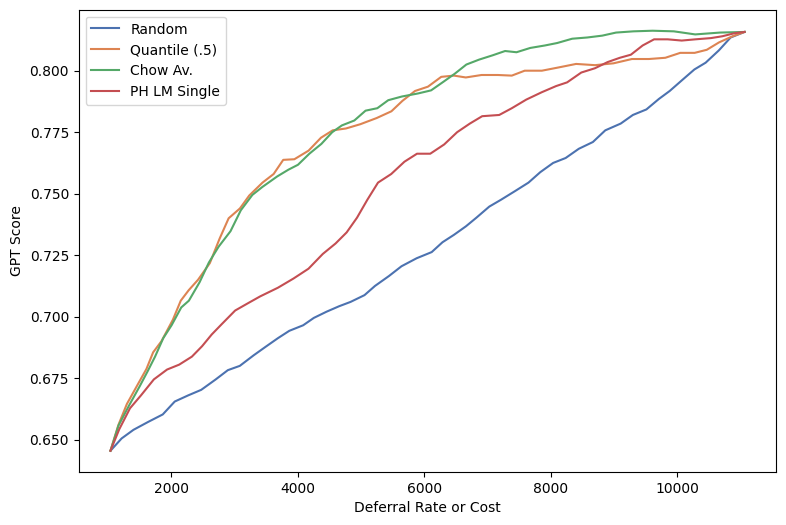

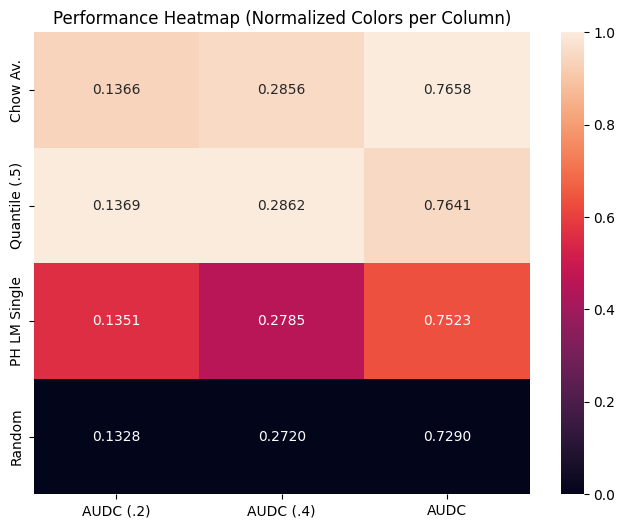

In [33]:

  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = baseline_casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS, primary_x="spend")
  true_baseline_results = results

# Single-Dim Knowledge 3-step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["knowledge"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  casc.register_axis_data(df2, ax_pos, small_cost, stage=1)
  casc.register_axis_data(df5, (2,), large_cost, stage=2)

  casc.normalize_dfs()
  casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    casc.fit_correctness_lm_at_tier(1,
          input_text_col="prompts_clean",
          output_text_col="res_clean",
          model_name="microsoft/deberta-v3-small",
          num_epochs=2,
          batch_size=16,
          learning_rate=2e-4,
          max_length=512,
          use_pos_weight=False,
          feature_cols=CHOW,
          normalize_features=True,
          threshold=0.5,
          score_col="post_hoc_conf",
          device=device,
          verbose=True
      )

  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df2['preferred_deferral']  = [(2,)]*len(df2)
  #casc.fit_post_hoc_lm_at(casc.origin, "prompts", "responses", num_epochs=3, device=device)
  #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
  #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)


Registered ['knowledge: 1'] | Shape: (4000, 52) | Cost: (8, 48)
Registered ['knowledge: 2'] | Shape: (4000, 52) | Cost: (70, 420)
[fit_correctness_lm_at_tier] tier=[(1,)] | device=cuda
  pooled examples/fold-train ~= sum over positions of (fold!=f) rows
  n_features: 13 | normalize_features: True
  correctness rate [(1,)]: 0.6817


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['fold'] = origin_fold


  fold 1/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 88.6814 seconds

================ Epoch 1/2 ================
Time Elapsed   : 99.11 seconds
Train Loss     : 0.6313
Validation Loss: 0.6311
Accuracy       : 0.6690
Precision (Mac): 0.3345
Recall (Macro) : 0.5000
F1-Score (Mac) : 0.4008
Finished epoch 2
Iteration 2 took 88.8069 seconds

================ Epoch 2/2 ================
Time Elapsed   : 99.12 seconds
Train Loss     : 0.6100
Validation Loss: 0.6202
Accuracy       : 0.6980
Precision (Mac): 0.7097
Recall (Macro) : 0.5575
F1-Score (Mac) : 0.5245
  fold 4/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 88.6315 seconds

================ Epoch 1/2 ================
Time Elapsed   : 98.95 seconds
Train Loss     : 0.6384
Validation Loss: 0.6151
Accuracy       : 0.6810
Precision (Mac): 0.3405
Recall (Macro) : 0.5000
F1-Score (Mac) : 0.4051


In [ ]:
  results = {}
  for d in def_cols:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, def_cols, primary_x = "spend")
  s_k_l_results = results

# Single-Dim Verify 3 Step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["verify"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  casc.register_axis_data(df3, ax_pos, small_cost, stage=1)
  casc.register_axis_data(df5, (2,), large_cost, stage=2)

  casc.normalize_dfs()
  casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    casc.fit_correctness_lm_at_tier(1,
          input_text_col="prompts_clean",
          output_text_col="res_clean",
          model_name="microsoft/deberta-v3-small",
          num_epochs=2,
          batch_size=16,
          learning_rate=2e-4,
          max_length=512,
          use_pos_weight=False,
          feature_cols=CHOW,
          normalize_features=True,
          threshold=0.5,
          score_col="post_hoc_conf",
          device=device,
          verbose=True
      )


  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df3['preferred_deferral']  = [(2,)]*len(df3)




In [ ]:
  results = {}
  for d in def_cols:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, def_cols, primary_x = "spend")
  s_v_l_results = results

# Single-Dim Structure 3 Step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  casc.register_axis_data(df4, ax_pos, small_cost, stage=1)
  casc.register_axis_data(df5, (2,), large_cost, stage=2)

  casc.normalize_dfs()
  casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    casc.fit_correctness_lm_at_tier(1,
          input_text_col="prompts_clean",
          output_text_col="res_clean",
          model_name="microsoft/deberta-v3-small",
          num_epochs=2,
          batch_size=16,
          learning_rate=2e-4,
          max_length=512,
          use_pos_weight=False,
          feature_cols=CHOW,
          normalize_features=True,
          threshold=0.5,
          score_col="post_hoc_conf",
          device=device,
          verbose=True
      )
  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df4['preferred_deferral']  = [(2,)]*len(df4)






In [ ]:
  results = {}
  for d in def_cols:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, def_cols, primary_x='spend')
  s_st_l_results = results


In [ ]:
r_subset = {}
def_col = "post_hoc_conf"
r_subset['Baseline S-L'] = true_baseline_results[def_col]
r_subset['S-K-L'] = s_k_l_results[def_col]
r_subset['S-St-L'] = s_st_l_results[def_col]
r_subset['S-V-L'] = s_v_l_results[def_col]
#r_subset['S-(St-K)-L'] = s_st_k_l_results['chow_av']
try:
  display_results(r_subset, r_subset.keys(), primary_x = "spend")
except:
  pass

## Linear 5 Step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["combined"], origin_cost = small_cost, metric_col=METRIC, k=4)
  casc.register_axis_data(df4, (1,), small_cost, stage=1)
  casc.register_axis_data(df3, (2,), small_cost, stage=2)
  casc.register_axis_data(df2, (3,), small_cost, stage=3)
  casc.register_axis_data(df5, (4,), large_cost, stage=4)


  casc.normalize_dfs()
  casc.compute_cv_splits()

  df1['preferred_deferral'] =  [(1,)]*len(df1)
  df4['preferred_deferral']  = [(2,)]*len(df4)
  df2['preferred_deferral']  = [(3,)]*len(df2)
  df3['preferred_deferral']  = [(4,)]*len(df3)
  #casc.pref_def_registry[casc.origin] = "preferred_deferral_lm"



In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS, primary_x = "spend")
  s_st_v_k_l_lin_results = results

## Three Way Multilabel

In [ ]:
device = "cuda"

In [ ]:
df_retain = df1.copy()


In [ ]:


for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc_retain = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure", "verify", "knowledge", "retain"], origin_cost = small_cost, metric_col=METRIC, k=4)
  casc_retain.register_axis_data(df4, (1,0,0,0), small_cost, stage=1)
  casc_retain.register_axis_data(df3, (0,1,0,0), small_cost, stage=1)
  casc_retain.register_axis_data(df2, (0,0,1,0), small_cost, stage=1)
  casc_retain.register_axis_data(df_retain, (0,0,0,1), (0,0), stage=1)
  casc_retain.register_axis_data(df5, (2,2,2,2), large_cost, stage=2)


  casc_retain.normalize_dfs()
  casc_retain.compute_cv_splits()

  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
  FIT_LM = True
  if FIT_LM:
      casc_retain.fit_correctness_lm_at_tier(1, "prompts", "res_clean",
        num_epochs=2,
        learning_rate=2e-5,
        feature_cols=CHOW,
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-small",
        verbose=True)
  FIT_AX_MODEL = True
  if FIT_AX_MODEL:
      casc_retain.fit_post_hoc_lm_at(casc_retain.origin, "prompts_clean", "res_clean",
        num_epochs=3,
        multilabel=True,
        learning_rate=2e-5,
        feature_cols=CHOW,
        recovery_fn = lambda base, axis: (axis > 0).astype(np.float32),
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-base",
        verbose=True)

    #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
    #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)
    #casc.set_cost_adjusted_pref(casc.origin, lam=1.5, cost_norm="max")
  df4['preferred_deferral']  = [(2,2,2,2,)]*len(df4)
  df3['preferred_deferral']  = [(2,2,2,2,)]*len(df3)
  df2['preferred_deferral']  = [(2,2,2,2,)]*len(df2)
  df_retain['preferred_deferral'] = [(2,2,2,2,)]*len(df_retain)

  casc_retain.pref_def_registry[casc_retain.origin] = "preferred_deferral_lm"



In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc_retain.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS, primary_x="spend")
  s_stvkr_l_results = results

In [ ]:
def sweep_retain_independent(
    casc,
    deferral_column="post_hoc_conf",
    rates=None,
    cost_col="inf_cost",
):
    import copy
    import types
    import numpy as np
    import pandas as pd

    if rates is None:
        rates = np.linspace(0, 1, 11)
    rates = np.unique(np.asarray(rates, dtype=float))

    if not np.isfinite(rates).all() or ((rates < 0) | (rates > 1)).any():
        raise ValueError("Rates must be finite and between 0 and 1.")

    origin = tuple(casc.origin)
    origin_stage = casc.stage_of[origin]
    stages = sorted(set(casc.stage_of.values()))

    if stages != [origin_stage, origin_stage + 1, origin_stage + 2]:
        raise ValueError(
            "Expected origin → intervention/retain → final topology."
        )

    # Shallow copy: reuse fitted frames, without changing the original object.
    evaluator = copy.copy(casc)
    original_ranker = casc._defer_mask_by_rate_over
    records = []

    for r_origin in rates:
        for r_mid in rates:
            wave = [0]

            def rank_this_wave(self, scores, pool_mask, unused_rate):
                if wave[0] >= 2:
                    raise RuntimeError(
                        "More than two deferral waves; check destinations."
                    )

                rate = (r_origin, r_mid)[wave[0]]
                wave[0] += 1

                if rate <= 0:
                    return np.zeros(len(scores), dtype=bool)
                if rate >= 1:
                    return pool_mask.copy()

                return original_ranker(scores, pool_mask, rate)

            evaluator._defer_mask_by_rate_over = types.MethodType(
                rank_this_wave, evaluator
            )

            # An interior placeholder keeps ranking enabled in the resolver.
            # The helper above supplies the actual rate for each wave.
            resolved = evaluator.resolve_full_deferred(
                origin,
                deferral_column,
                deferral_rate=0.5,
                cost_col=cost_col,
                rank_scope="tier",
            )

            final_positions = [
                tuple(p) for p in resolved["final_position"]
            ]

            records.append({
                "r_origin": float(r_origin),
                "r_mid": float(r_mid),
                "accuracy": float(resolved[casc.metric_col].mean()),
                "spend": float(resolved["resolved_cost"].mean()),
                "large_rate": np.mean([
                    casc.stage_of[p] == stages[-1]
                    for p in final_positions
                ]),
                "original_sweep": bool(r_origin == r_mid),
            })

    return pd.DataFrame(records)

In [ ]:
retain_points = sweep_retain_independent(
    casc_retain,
    deferral_column="post_hoc_conf",  # or "normed_log_chow_av"
)

# Original equal-rate sweep.
diagonal = retain_points[
    retain_points["original_sweep"]
].sort_values("r_origin")

# Expanded empirical frontier.
ordered = retain_points.sort_values(
    ["spend", "accuracy"], ascending=[True, False]
).drop_duplicates("spend")

retain_frontier = ordered[
    ordered["accuracy"] > ordered["accuracy"].cummax().shift(
        fill_value=-np.inf
    )
]

plt.figure(figsize=(8, 5))
plt.plot(
    diagonal["spend"], diagonal["accuracy"],
    "--", label="Retain: original coupled rates",
)
plt.plot(
    retain_frontier["spend"], retain_frontier["accuracy"],
    label="Retain: independent rates",
)
plt.xlabel("Mean accumulated inference cost")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

display(retain_frontier)

In [ ]:
df5['inf_cost'].mean()

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure", "verify", "knowledge"], origin_cost = small_cost, metric_col=METRIC, k=4)
  casc.register_axis_data(df4, (1,0,0,), small_cost, stage=1)
  casc.register_axis_data(df3, (0,1,0,), small_cost, stage=1)
  casc.register_axis_data(df2, (0,0,1,), small_cost, stage=1)
  #casc.register_axis_data(df_retain, (0,0,0,1), (0,0), stage=1)
  casc.register_axis_data(df5, (2,2,2,), large_cost, stage=2)


  casc.normalize_dfs()
  casc.compute_cv_splits()

  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
  FIT_LM = False
  if FIT_LM:
      casc.fit_correctness_lm_at_tier(1, "prompts", "res_clean",
        num_epochs=1,
        learning_rate=2e-5,
        feature_cols=CHOW,
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-small",
        verbose=True)
  FIT_AX_MODEL = True
  if FIT_AX_MODEL:
      casc.fit_post_hoc_lm_at(casc.origin, "prompts_clean", "res_clean",
        num_epochs=1,
        multilabel=CHOW,
        learning_rate=2e-5,
        feature_cols=CHOW,
        recovery_fn = lambda base, axis: (axis > base).astype(np.float32),
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-small",
        verbose=True)

    #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
    #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)
    #casc.set_cost_adjusted_pref(casc.origin, lam=1.5, cost_norm="max")
  df4['preferred_deferral']  = [(2,2,2,)]*len(df4)
  df3['preferred_deferral']  = [(2,2,2,)]*len(df3)
  df2['preferred_deferral']  = [(2,2,2,)]*len(df2)
  df_retain['preferred_deferral'] = [(2,2,2,)]*len(df_retain)

  casc.pref_def_registry[casc.origin] = "preferred_deferral_lm"



In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS, primary_x="spend")
  s_stvk_l_results = results

In [ ]:
def sweep_two_thresholds(
    casc,
    base_score_col="post_hoc_conf",
    mid_score_col="post_hoc_conf",
    destination_col="preferred_deferral_lm",
    final_position=(2, 2, 2),
    cost_col="inf_cost",
    grid_size=31,
):
    import numpy as np
    import pandas as pd

    origin = tuple(casc.origin)
    final_position = tuple(final_position)
    base = casc.registry[origin]
    large = casc.registry[final_position]
    metric = casc.metric_col
    n = len(base)

    # Assumes matching row order, as in your current resolver.
    destinations = [tuple(v) for v in base[destination_col]]
    positions = sorted(set(destinations))

    for p in positions + [final_position]:
        if not casc.registry[p].index.equals(base.index):
            raise ValueError(f"Index/order mismatch at {p}")

    s_base = base[base_score_col].to_numpy(dtype=float)
    y_base = base[metric].to_numpy(dtype=float)
    c_base = base[cost_col].to_numpy(dtype=float)
    y_large = large[metric].to_numpy(dtype=float)
    c_large = large[cost_col].to_numpy(dtype=float)

    # Assemble each row's selected intervention outcome and current score.
    y_mid = np.empty(n)
    c_mid = np.empty(n)
    s_mid = np.empty(n)

    for p in positions:
        mask = np.array([d == p for d in destinations])
        frame = casc.registry[p]
        y_mid[mask] = frame[metric].to_numpy(dtype=float)[mask]
        c_mid[mask] = frame[cost_col].to_numpy(dtype=float)[mask]
        s_mid[mask] = frame[mid_score_col].to_numpy(dtype=float)[mask]

    if not np.isfinite(s_base).all() or not np.isfinite(s_mid).all():
        raise ValueError("Deferral scores contain NaN or infinite values.")

    def thresholds(scores):
        return np.unique(np.r_[
            -np.inf,
            np.quantile(scores, np.linspace(0, 1, grid_size)),
            np.inf,
        ])

    records = []
    for t_base in thresholds(s_base):
        enter_mid = s_base > t_base

        for t_mid in thresholds(s_mid):
            enter_large = enter_mid & (s_mid > t_mid)

            outcome = y_base.copy()
            outcome[enter_mid] = y_mid[enter_mid]
            outcome[enter_large] = y_large[enter_large]

            cost = (
                c_base
                + enter_mid * c_mid
                + enter_large * c_large
            )

            records.append({
                "t_base": t_base,
                "t_mid": t_mid,
                "accuracy": outcome.mean(),
                "spend": cost.mean(),
                "intervention_rate": enter_mid.mean(),
                "large_rate": enter_large.mean(),
            })

    return pd.DataFrame(records)



In [ ]:
def sweep_small_large(
    casc,
    score_col="post_hoc_conf",
    final_position=(2, 2, 2),
    cost_col="inf_cost",
    grid_size=101,
):
    base = casc.registry[casc.origin]
    large = casc.registry[tuple(final_position)]

    if not large.index.equals(base.index):
        raise ValueError("Base and large index/order mismatch.")

    score = base[score_col].to_numpy(dtype=float)
    if not np.isfinite(score).all():
        raise ValueError("Deferral scores contain NaN or infinite values.")

    y_base = base[casc.metric_col].to_numpy(dtype=float)
    y_large = large[casc.metric_col].to_numpy(dtype=float)
    c_base = base[cost_col].to_numpy(dtype=float)
    c_large = large[cost_col].to_numpy(dtype=float)

    thresholds = np.unique(np.r_[
        -np.inf,
        np.quantile(score, np.linspace(0, 1, grid_size)),
        np.inf,
    ])

    records = []
    for threshold in thresholds:
        defer = score > threshold
        records.append({
            "threshold": threshold,
            "accuracy": np.where(defer, y_large, y_base).mean(),
            "spend": (c_base + defer * c_large).mean(),
            "large_rate": defer.mean(),
        })

    return pd.DataFrame(records)


def nondominated_frontier(points):
    ordered = points.sort_values(
        ["spend", "accuracy"], ascending=[True, False]
    ).drop_duplicates("spend")

    return ordered[
        ordered["accuracy"] > ordered["accuracy"].cummax().shift(
            fill_value=-np.inf
        )
    ]


# Use the same origin score as the intervention sweep.
small_large_points = sweep_small_large(
    casc,
    score_col="post_hoc_conf",
    final_position=(2, 2, 2),
)

frontier = nondominated_frontier(points)
small_large_frontier = nondominated_frontier(small_large_points)

plt.figure(figsize=(8, 5))
plt.plot(
    frontier["spend"], frontier["accuracy"],
    label="Small → intervention → large",
)
plt.plot(
    small_large_frontier["spend"],
    small_large_frontier["accuracy"],
    linestyle="--",
    label="Small → large",
)
plt.xlabel("Mean accumulated inference cost")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def sweep_recovery_gated(
    casc,
    final_position=(2, 2, 2),
    recovery_cols=None,
    base_score_col="post_hoc_conf",
    mid_score_col="post_hoc_conf",
    cost_col="inf_cost",
    grid_size=15,
):
    """
    HIGH recovery prediction = try intervention.
    HIGH base/mid deferral score = escalate to large.

    Policy:
      recovery >= threshold -> selected intervention -> possibly large
      otherwise             -> keep base or go directly to large

    Recovery predictions are used as ranking signals, not calibrated net gains.
    """
    origin = tuple(casc.origin)
    final_position = tuple(final_position)
    base = casc.registry[origin]
    large = casc.registry[final_position]
    metric = casc.metric_col
    n = len(base)

    if recovery_cols is None:
        recovery_cols = {
            ax: f"post_hoc_lm_{ax}"
            for ax in casc.axes_names
            if ax != "retain"
        }

    if not recovery_cols:
        raise ValueError("No intervention recovery columns supplied.")

    # Candidate positions are the origin's +1 axis neighbours.
    positions = []
    for ax in recovery_cols:
        axis_index = casc.axes_names.index(ax)
        p = list(origin)
        p[axis_index] += 1
        positions.append(tuple(p))

    for p in positions + [final_position]:
        if not casc.registry[p].index.equals(base.index):
            raise ValueError(f"Index/order mismatch at {p}")

    P = base[list(recovery_cols.values())].to_numpy(dtype=float)
    if not np.isfinite(P).all():
        raise ValueError("Recovery predictions contain NaN/infinite values.")

    # Reproduce argmax destination selection using existing fitted predictions.
    chosen = P.argmax(axis=1)
    recovery = P[np.arange(n), chosen]

    def values(frame, column):
        result = frame[column].to_numpy(dtype=float)
        if not np.isfinite(result).all():
            raise ValueError(f"{column!r} contains NaN/infinite values.")
        return result

    y_base = values(base, metric)
    c_base = values(base, cost_col)
    s_base = values(base, base_score_col)
    y_large = values(large, metric)
    c_large = values(large, cost_col)

    y_mid = np.empty(n)
    c_mid = np.empty(n)
    s_mid = np.empty(n)

    for j, p in enumerate(positions):
        mask = chosen == j
        frame = casc.registry[p]
        y_mid[mask] = values(frame, metric)[mask]
        c_mid[mask] = values(frame, cost_col)[mask]
        s_mid[mask] = values(frame, mid_score_col)[mask]

    def thresholds(scores):
        return np.unique(np.r_[
            -np.inf,
            np.quantile(scores, np.linspace(0, 1, grid_size)),
            np.inf,
        ])

    records = []

    for t_recovery in thresholds(recovery):
        try_mid = recovery >= t_recovery

        for t_base in thresholds(s_base):
            direct_large = ~try_mid & (s_base > t_base)

            for t_mid in thresholds(s_mid):
                after_mid_large = try_mid & (s_mid > t_mid)
                use_large = direct_large | after_mid_large

                outcome = y_base.copy()
                outcome[try_mid] = y_mid[try_mid]
                outcome[use_large] = y_large[use_large]

                # Base is already computed. Every further call adds its cost.
                spend = (
                    c_base
                    + try_mid * c_mid
                    + use_large * c_large
                )

                row = {
                    "t_recovery": t_recovery,
                    "t_base": t_base,
                    "t_mid": t_mid,
                    "accuracy": outcome.mean(),
                    "spend": spend.mean(),
                    "intervention_rate": try_mid.mean(),
                    "direct_large_rate": direct_large.mean(),
                    "after_mid_large_rate": after_mid_large.mean(),
                    "large_rate": use_large.mean(),
                }

                for j, ax in enumerate(recovery_cols):
                    row[f"rate_{ax}"] = (try_mid & (chosen == j)).mean()

                records.append(row)

    return pd.DataFrame(records)


def nondominated_frontier(points):
    ordered = points.sort_values(
        ["spend", "accuracy"], ascending=[True, False]
    ).drop_duplicates("spend")

    return ordered[
        ordered["accuracy"] > ordered["accuracy"].cummax().shift(
            fill_value=-np.inf
        )
    ].copy()

In [ ]:
gated_points = sweep_recovery_gated(
    casc,
    recovery_cols={
        "structure": "post_hoc_lm_structure",
        "verify": "post_hoc_lm_verify",
        "knowledge": "post_hoc_lm_knowledge",
    },
    base_score_col="post_hoc_conf",
    mid_score_col="post_hoc_conf",
    final_position=(2, 2, 2),
    grid_size=15,
)

gated_frontier = nondominated_frontier(gated_points)

# Recompute the straight small-large comparison using the earlier function.
small_large_points = sweep_small_large(
    casc,
    score_col="post_hoc_conf",
    final_position=(2, 2, 2),
)
small_large_frontier = nondominated_frontier(small_large_points)

plt.figure(figsize=(8, 5))
plt.plot(
    gated_frontier["spend"],
    gated_frontier["accuracy"],
    label="Recovery-gated interventions + direct large",
)
plt.plot(
    small_large_frontier["spend"],
    small_large_frontier["accuracy"],
    "--",
    label="Small → large",
)

# Previous two-threshold intervention sweep, if still available.
if "points" in globals():
    previous_frontier = nondominated_frontier(points)
    plt.plot(
        previous_frontier["spend"],
        previous_frontier["accuracy"],
        ":",
        label="Previous two-threshold cascade",
    )

plt.xlabel("Mean accumulated inference cost")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

display(gated_frontier[[
    "accuracy", "spend",
    "intervention_rate", "direct_large_rate",
    "after_mid_large_rate",
    "rate_structure", "rate_verify", "rate_knowledge",
    "t_recovery", "t_base", "t_mid",
]])

In [ ]:
points = sweep_two_thresholds(
    casc,
    base_score_col="post_hoc_conf",
    mid_score_col="post_hoc_conf",
    final_position=(2, 2, 2),
)

# Empirical nondominated points: best accuracy for increasing spend.
ordered = points.sort_values(
    ["spend", "accuracy"], ascending=[True, False]
).drop_duplicates("spend")

frontier = ordered[
    ordered["accuracy"] > ordered["accuracy"].cummax().shift(
        fill_value=-np.inf
    )
]

plt.plot(frontier["spend"], frontier["accuracy"], label="Two-threshold sweep")
plt.xlabel("Mean accumulated inference cost")
plt.ylabel("Accuracy")
plt.legend()

In [ ]:
results = {}
for d in ['random', 'normed_chow_quantile', 'normed_log_chow_av', 'post_hoc_conf']:
    results[d] = casc.gain_per_cost_cascade_over_rates(second_hop_score=d)
display_results(results, list(results.keys()), primary_x="spend")
results_ns = results

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
df0 = casc.registry[casc.origin]
for d in DELEGATE_COLUMNS:
    assert d in df0.columns, f"{d} missing from origin frame"
    v = df0[d].iloc[0]
    assert np.isscalar(v) or isinstance(v, (int, float, np.floating)), \
        f"{d} looks like a destination/tuple column, not a score"
print("delegate score columns OK; pref_def_registry[origin] =",
      casc.pref_def_registry[casc.origin])

In [ ]:
for i, df in enumerate(dataframes):
  df[['prompts', 'normed_log_chow_av', 'responses', 'gpt_score']].to_csv(f"df{i}.csv")

In [ ]:
r_subset = {}
def_col = 'normed_log_chow_av'
r_subset['Baseline S-L'] = true_baseline_results[def_col]

r_subset['S-(St-v-K)-L'] = s_stvk_l_results[def_col]
r_subset['S-(St-v-K-r)-L'] = s_stvkr_l_results[def_col]
r_subset['S-St-v-K-L'] = s_st_v_k_l_lin_results[def_col]
r_subset['S-V-L'] = s_k_l_results[def_col]
r_subset['S-NS-L'] = results_ns[def_col]
#r_subset['S-St-L'] = s_st_l_results[def_col]
#r_subset['S-V-L'] = s_v_l_results[def_col]
try:
  display_results(r_subset, r_subset.keys(), primary_x = "spend")
except:
  pass

## Routing Baseline

In [ ]:
# ---- ROUTING BASELINE ----------------------------------------------------
# Single tier: the router picks ONE candidate model per sample using inputs
# only, and pays only that model's inference cost. df1 is the input-only,
# zero-cost origin carrier; df4 / df5 are the two candidate models.

router = colab_llm_utils.cascades.MultiaxialCascade.build_router_cascade(
    origin_df=df1,
    candidate_dfs=[df1, df2, df3, df4, df5],
    candidate_names=["small", "rag", "verify", "structure", "large"],      # one axis (=class) per candidate
    candidate_costs=[small_cost, small_cost, (16, 96), small_cost, large_cost],     # per-candidate inference cost
    metric_col="correct",
    k=4, seed=42,
)
# build_router_cascade already calls register_axis_data + compute_cv_splits.
# Candidate "mid"  -> position (1, 0)
# Candidate "large"-> position (0, 1)

# --- Learned router: train the selector on INPUT text only, no keep class ---
router.fit_router_lm_at(
    position=router.origin,
    input_text_col="prompts",              # inputs only; no response concat
    num_epochs=2, batch_size=8,
)
# writes df1['preferred_deferral_lm'] (chosen candidate position),



In [ ]:
import types
import pandas as pd

# The attached cascades.py CALLS self.resolve_full_deferred_old(...) in
# route_at_tier (line 1736) and full_threshold_sim_temp (line 1435) but never
# DEFINES it. This supplies the missing single-hop per-row resolver: for each
# row it returns that row's record from the destination frame named by the
# per-row position column (e.g. 'preferred_routing_lm').
def resolve_full_deferred_old(self, from_position, pref_def_column='preferred_deferral'):
    from_position = tuple(from_position)
    src = self.registry[from_position]
    dests = src[pref_def_column].values
    rows = [self.registry[tuple(d)].loc[i] for i, d in zip(src.index, dests)]
    out = pd.DataFrame(rows)
    out.index = src.index
    return out

# Bind onto the already-fitted instance -> no re-import, no re-fit.
router.resolve_full_deferred_old = types.MethodType(resolve_full_deferred_old, router)

print("Patched: resolve_full_deferred_old is now available on router.")

In [ ]:
router_results = {}
router_results["router_lm"] = router.route_at_tier(route_column="preferred_routing_lm")


In [ ]:
router_results["router_cost_sweep"] = router.route_cost_sweep(score_mode="expensive")

In [ ]:
router_results['Baseline S-L'] = true_baseline_results[def_col]
router_results['S-V-L'] = s_v_l_results[def_col]
router_results['Multiax'] = s_stvkr_l_results[def_col]


display_results(router_results, list(router_results.keys()), primary_x='spend', calc_cal_results = False)

In [ ]:
df_retain['post_hoc_conf'] = df1['post_hoc_conf']

In [ ]:
for df in dataframes:
  print(df['inf_cost'].sum())

In [ ]:
df_retain['post_hoc_conf']  = df1['post_hoc_conf'] + 1
df1['preferred_deferral_lm'] = [(0,0,0,1,)]* len(df1)
#df1_prefcop = df1['preferred_deferral_lm'].copy()
#df1['preferred_deferral_lm'] = df1_prefcop

In [ ]:
df2[df1_prefcop == (0, 0, 1, 0,)]["inf_cost"].mean()

In [ ]:
df2[~(df1_prefcop == (0, 0, 1, 0,))]["inf_cost"].mean()

In [ ]:
df2[df1_prefcop == (0, 0, 1, 0,)][['prompts', 'prompt_len', 'output_len', 'inf_cost']]

In [ ]:
df5[df1_prefcop == (0, 0, 1, 0,)][['prompt_len', 'output_len', 'inf_cost']]

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
df1[['prompts', 'responses', 'inf_cost']].head()

In [ ]:
, df4[['prompts', 'responses', 'inf_cost']].head()

In [ ]:
df5[['prompts', 'responses', 'inf_cost']].head()

In [ ]:
logits = model(input_ids, attention_mask)

In [ ]:
logits